In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import ee


In [4]:
df = pd.read_csv("../data/raw/harbor_water_quality.csv", low_memory=False)
print(df.shape)

(98288, 100)


Load and select

In [5]:
#The chl-a column name contains special characters (µ, '), so find it by its start
chl_col = [c for c in df.columns if c.startswith("Top Active Chlorophyll")][0]

#Keep only the columns we need with short names
d = df[["Sampling Location", "Sample Date", "Sample Time", "Lat", "Long", chl_col]].copy()
d = d.rename(columns={"Sampling Location": "station", chl_col: "chl"})

#Convert text to real dates and numbers
d["date"] = pd.to_datetime(d["Sample Date"], format="%m/%d/%Y")
d["chl"] = pd.to_numeric(d["chl"], errors="coerce")

#Keep 2016+ (Sentinel-2 era) and rows with a chl-a value
d =d[(d["date"] >= "2016-01-01") & d["chl"].notna()]

print(len(d), "samples at", d["station"].nunique(), "stations,",
      d["date"].min().date(), "to", d["date"].max().date())

18980 samples at 91 stations, 2016-01-04 to 2025-12-16


Sample per year and month

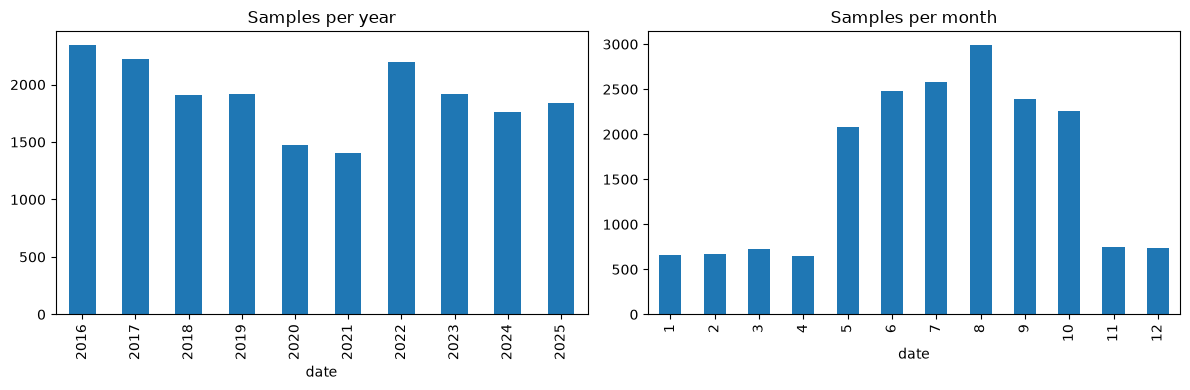

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d.groupby(d["date"].dt.year).size().plot.bar(ax=ax[0], title="Samples per year")
d.groupby(d["date"].dt.month).size().plot.bar(ax=ax[1], title="Samples per month")
plt.tight_layout()
plt.show()

Samples per station

In [7]:
counts = d["station"].value_counts()
print(counts.describe().round(0))
print("\nFewest samples:\n", counts.tail(5))

count     91.0
mean     209.0
std       54.0
min        1.0
25%      199.0
50%      220.0
75%      239.0
max      269.0
Name: count, dtype: float64

Fewest samples:
 station
GHC        77
HOB        74
NC         23
J15        23
ERT Blk     1
Name: count, dtype: int64


chl-a values

count    18980.0
mean        22.0
std         39.0
min          0.2
25%          3.7
50%         10.8
75%         25.6
max       1122.0
Name: chl, dtype: float64
Share above 20 µg/L (eutrophic): 32%


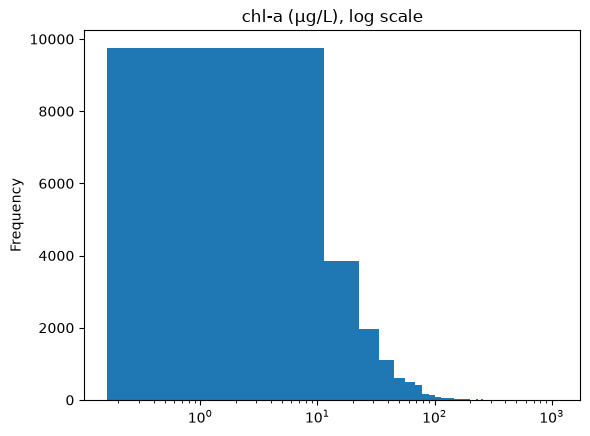

In [8]:
print(d["chl"].describe().round(1))
print(f"Share above 20 µg/L (eutrophic): {(d['chl'] > 20).mean():.0%}")

d["chl"].plot.hist(bins=100, logx=True, title="chl-a (µg/L), log scale")
plt.show()

Open water vs creeks

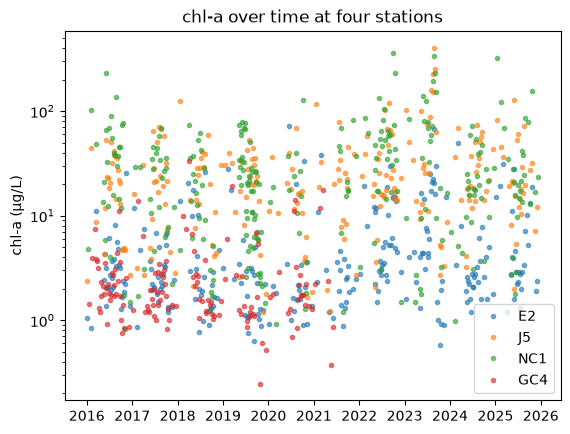

In [9]:
for s in ["E2", "J5", "NC1", "GC4"]:
    x = d[d["station"] == s].sort_values("date")
    plt.plot(x["date"], x["chl"], ".", label=s, alpha=0.6)
plt.yscale("log")
plt.ylabel("chl-a (µg/L)")
plt.legend()
plt.title("chl-a over time at four stations")
plt.show()

* When most samples are taken
* Which station looks odd (ERT Blk)
* How chl-a differs between stations (Gowanus is low, Newtown Creek is high)

Count the days with a Sentinel-2 image over Newtown Creek (2016–2025), and how many have < 20% cloud. Cloud % is per tile, so this is a rough estimate

Days with an image: 1358
Days with < 20% cloud: 397


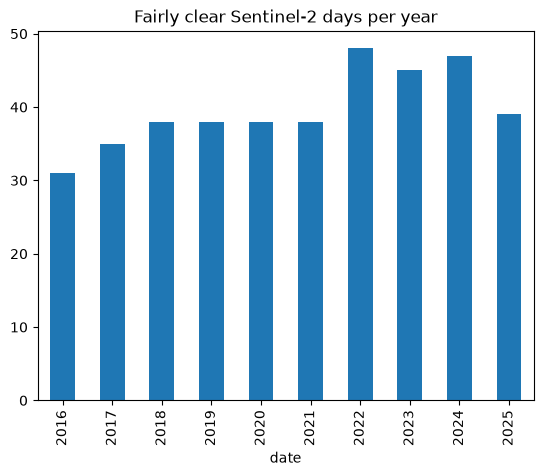

In [ ]:
ee.Initialize(project="alien-vim-299320")

point = ee.Geometry.Point([-73.94, 40.73])   #Newtown Creek
col = (ee.ImageCollection("COPERNICUS/S2_HARMONIZED")   #Level-1C, as in the original paper
       .filterBounds(point)
       .filterDate("2016-01-01", "2026-01-01"))

imgs = pd.DataFrame({
    "time": col.aggregate_array("system:time_start").getInfo(),
    "cloud": col.aggregate_array("CLOUDY_PIXEL_PERCENTAGE").getInfo(),
})
imgs["date"] = pd.to_datetime(imgs["time"], unit="ms").dt.normalize()
imgs = imgs.groupby("date")["cloud"].min().reset_index()   #one row per day

print("Days with an image:", len(imgs))
print("Days with < 20% cloud:", (imgs["cloud"] < 20).sum())
imgs[imgs["cloud"] < 20].groupby(imgs["date"].dt.year).size().plot.bar(
    title="Fairly clear Sentinel-2 days per year")
plt.show()

Count the water samples that have a clear image (< 20% cloud) within ±0, ±1, ±3 and ±5 days 

In [ ]:
clear = imgs.loc[imgs["cloud"] < 20, "date"]

for k in [0, 1, 3, 5]:
    #all dates within ±k days of a clear image
    window = {c + pd.Timedelta(days=o) for c in clear for o in range(-k, k + 1)}
    n = d["date"].isin(window).sum()
    print(f"±{k} days: {n} samples ({n / len(d):.0%})")

±0 days: 2350 samples (12%)
±1 days: 6161 samples (32%)
±3 days: 10842 samples (57%)
±5 days: 13843 samples (73%)
